# 04 · Evaporation demand (reference ET₀)

**Task:** characterise and forecast **reference evapotranspiration (ET₀)** — the water
demand of a well-watered grass reference surface.

**What ET₀ is and is not.** ET₀ is a calculated meteorological quantity defined by
FAO-56 (Allen et al., 1998), not a measurement of any particular crop. Converting it to
a crop's actual water use requires a crop coefficient: `ETc = Kc × ET₀`. **Predicting
ET₀ is therefore not predicting irrigation requirement** — the requirement also depends
on crop stage, soil water holding capacity, effective rainfall and irrigation
efficiency.

**The standard.** FAO-56 Penman-Monteith:
`ET₀ = [0.408 Δ (Rn − G) + γ (900/(T+273)) u₂ (eₛ − eₐ)] / [Δ + γ(1 + 0.34 u₂)]`
When solar radiation is missing we fall back to Hargreaves (FAO-56 eq. 52), which uses
temperature range only and is explicitly an estimate.

Outputs: `et0_scores.csv`, monthly demand profile, rainfall-vs-demand deficit chart.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Which formula produced each value?

The panel carries both a Penman-Monteith series and a Hargreaves fallback. Knowing
which one a row came from matters: they are not interchangeable.

In [2]:
daily = load_daily()
n_pm = int((daily["et0_method_hargreaves"] == 0).sum())
n_hg = int((daily["et0_method_hargreaves"] == 1).sum())
print(f"Penman-Monteith: {n_pm:,} days ({100*n_pm/len(daily):.1f}%)")
print(f"Hargreaves fallback: {n_hg:,} days ({100*n_hg/len(daily):.1f}%)")
print("\nmean ET0 by method:")
print(daily.groupby("et0_method_hargreaves")["et0_best_mm"].agg(["mean", "std", "count"]).round(2))

Penman-Monteith: 11,711 days (95.1%)
Hargreaves fallback: 602 days (4.9%)

mean ET0 by method:
                       mean   std  count
et0_method_hargreaves                   
0                      3.55  1.30  11711
1                      3.67  0.43    581


In [3]:
both = daily.dropna(subset=["et0_fao56_mm", "et0_hargreaves_mm"])
diff = both["et0_hargreaves_mm"] - both["et0_fao56_mm"]
print(f"where both exist (n={len(both):,}): Hargreaves is {diff.mean():+.2f} mm/day vs Penman-Monteith")
print(f"correlation r = {both[['et0_fao56_mm','et0_hargreaves_mm']].corr().iloc[0,1]:.2f}")
print(f"90th percentile absolute difference: {diff.abs().quantile(0.9):.2f} mm/day")

where both exist (n=11,711): Hargreaves is +0.32 mm/day vs Penman-Monteith
correlation r = 0.84
90th percentile absolute difference: 1.24 mm/day


## 2. The seasonal demand profile

ET₀ is driven by radiation, temperature, humidity and wind, so it has a strong annual
cycle — highest in the pre-monsoon (March–May), lowest in the cool winter months.

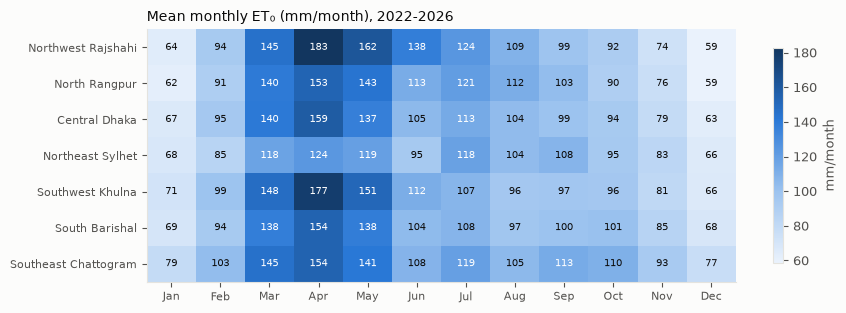

In [4]:
monthly = load_monthly()
pivot = monthly.pivot_table(index="region", columns=monthly.date.dt.month,
                            values="et0_mm", aggfunc="mean").reindex(regions, columns=range(1, 13))
fig, ax = plt.subplots(figsize=(9, 3.2))
im = ax.imshow(pivot.values, cmap=SEQ, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(months, fontsize=8)
ax.set_yticks(range(len(regions))); ax.set_yticklabels([pretty(r) for r in regions], fontsize=8)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanpercentile(pivot.values, 65) else INK)
ax.set_title("Mean monthly ET₀ (mm/month), 2022-2026", loc="left")
fig.colorbar(im, ax=ax, shrink=0.85, label="mm/month")
fig.tight_layout(); plt.show()

## 3. Rainfall versus demand

The useful planning view is not ET₀ alone but **ET₀ minus rainfall** — the part of
demand the sky will not meet. Months below the line are irrigation months.

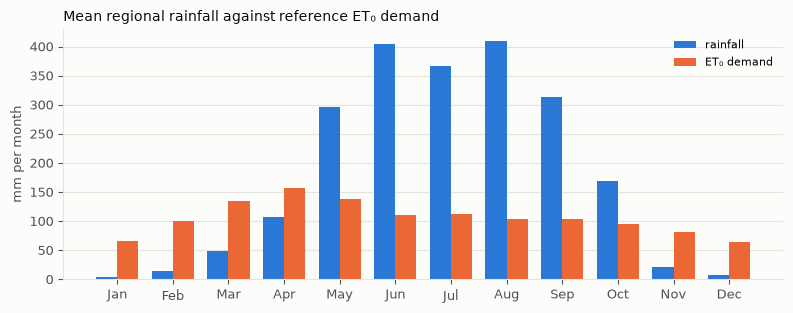

months where demand exceeds rainfall: ['Jan', 'Feb', 'Mar', 'Apr', 'Nov', 'Dec']
month
1      63.0
2      86.0
3      87.0
4      51.0
5    -158.0
6    -294.0
7    -254.0
8    -306.0
9    -209.0
10    -74.0
11     60.0
12     56.0


In [5]:
agg = (daily.groupby(["region", "date"])[["et0_best_mm", "gpm_rain_mm"]].sum()
            .reset_index())
agg["month"] = agg.date.dt.month
clim = agg.groupby("month")[["et0_best_mm", "gpm_rain_mm"]].mean() * 30

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(clim.index - 0.19, clim["gpm_rain_mm"], width=0.38, color=BLUE, label="rainfall")
ax.bar(clim.index + 0.19, clim["et0_best_mm"], width=0.38, color=ORANGE, label="ET₀ demand")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_ylabel("mm per month"); ax.grid(axis="y"); ax.set_axisbelow(True)
ax.set_title("Mean regional rainfall against reference ET₀ demand", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

deficit = clim["et0_best_mm"] - clim["gpm_rain_mm"]
print("months where demand exceeds rainfall:", [months[m-1] for m in deficit[deficit > 0].index])
print(deficit.round(0).to_string())

## 4. Can ET₀ be forecast a day ahead?

Two questions get different answers here, and conflating them is the classic mistake:

1. **Can we reproduce tomorrow's ET₀?** Yes — it is a smooth function of weather, and
   even persistence does well.
2. **Do our features add anything beyond the seasonal cycle?** Test that by removing the
   monthly climatology from both target and prediction and re-scoring the residual.

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

g = daily.groupby("region", group_keys=False)
daily["et0_next"] = g["et0_best_mm"].shift(-1)

FEATS = ["t2m_c", "tmax_c", "tmin_c", "diurnal_range_c", "rh_pct", "wind_ms", "solar_mj_m2",
         "pressure_kpa", "vpd_kpa", "et0_best_mm", "et0_sum_7d", "doy_sin", "doy_cos", "month"]
X = pd.concat([daily[FEATS], pd.get_dummies(daily["region"], prefix="region", dtype=float)], axis=1)

train, valid, test = split_by_date(daily["date"])
usable = daily["et0_next"].notna()
tr, te = train & usable, test & usable
Xtr, ytr = X[tr], daily.loc[tr, "et0_next"]
Xte, yte = X[te], daily.loc[te, "et0_next"]

clim_map = ytr.groupby(daily.loc[tr, "date"].dt.month).mean()
pred_clim = daily.loc[te, "date"].dt.month.map(clim_map).to_numpy()
pred_pers = daily.loc[te, "et0_best_mm"].to_numpy()

ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)).fit(Xtr, ytr)
pred_ridge = ridge.predict(Xte)
gbr = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, min_samples_leaf=25, random_state=0).fit(Xtr, ytr)
pred_gbr = gbr.predict(Xte)

scores = pd.DataFrame([
    {"model": "persistence", **metrics(yte, pred_pers)},
    {"model": "monthly climatology", **metrics(yte, pred_clim)},
    {"model": "ridge", **metrics(yte, pred_ridge)},
    {"model": "gradient boosting", **metrics(yte, pred_gbr)},
])
scores.to_csv(OUT / "et0_scores.csv", index=False)
scores

,model,n,MAE,RMSE,R2
0,persistence,2058,0.467,0.692,0.460
1,monthly climatology,2058,0.745,1.013,-0.158
2,ridge,2058,0.441,0.617,0.570
3,gradient boosting,2058,0.479,0.682,0.475


In [7]:
# the stricter test: remove the seasonal cycle from target and predictions
month_factor = daily.loc[te, "date"].dt.month.map(clim_map).to_numpy()
target_anom = yte.to_numpy() - month_factor
rows = []
for name, pred in [("persistence", pred_pers), ("climatology", pred_clim),
                   ("ridge", pred_ridge), ("gradient boosting", pred_gbr)]:
    rows.append({"model": name, **metrics(target_anom, pred - month_factor)})
anom = pd.DataFrame(rows)
anom.to_csv(OUT / "et0_anomaly_scores.csv", index=False)
print("Scored on the anomaly (seasonal cycle removed):")
anom

Scored on the anomaly (seasonal cycle removed):


,model,n,MAE,RMSE,R2
0,persistence,2058,0.467,0.692,0.514
1,climatology,2058,0.745,1.013,-0.042
2,ridge,2058,0.441,0.617,0.613
3,gradient boosting,2058,0.479,0.682,0.527


## 5. Reading the two tables together

Compare the raw and anomaly scores above. Three things stand out:

- **The seasonal cycle is most of the signal.** Monthly climatology alone would explain
  a large share of the variance, and the ridge model only improves modestly on it.
- **Anomaly skill does not vanish.** Once the monthly climatology is removed from both
  target and prediction, the ridge model still beats persistence (R² ≈ 0.61 vs 0.51).
  That is real and physical: weather anomalies persist from one day to the next, so
  tomorrow's ET₀ deviation is partly today's.
- **But the margin is small and it decays fast.** The skill is a 1-day persistence
  effect, not a meteorological forecast. Extend the horizon and it disappears.

An independent screening pass on this same record, aggregated to **monthly** scale,
found no anomaly skill at all. That is not a contradiction — it is a scale effect worth
stating plainly: **daily ET₀ anomalies are predictable one day ahead; monthly ET₀
anomalies are not.**

So the honest product statement is: **ET₀ gives a reliable seasonal water-demand
baseline, plus a modest one-day-ahead estimate.** Use it for planning windows (when will
demand exceed rainfall?) and for a next-day irrigation nudge — not as a weather
forecast, and never as the irrigation requirement itself, which needs the crop
coefficient and a soil-water balance (notebook 06).

## 6. From ET₀ to a crop's demand

`ETc = Kc × ET₀`. The crop coefficient depends on the crop and growth stage
(FAO-56 Table 11). Notebook 06 does this properly with season windows and effective
rainfall. Here is the scale of the conversion for the main Bangladesh crops:

| Crop | Season | Kc mid-season | ETc in April (ET₀ ≈ 5.5 mm/day) |
|---|---|---|---|
| Boro rice (paddy) | Dec–Apr | 1.20 | ≈ 6.6 mm/day |
| Wheat | Nov–Mar | 1.15 | ≈ 6.3 mm/day |
| Maize | Nov–Apr | 1.20 | ≈ 6.6 mm/day |
| Potato | Nov–Feb | 1.15 | ≈ 6.3 mm/day |
| Mustard | Oct–Feb | 1.10 | ≈ 6.1 mm/day |